# Fine-tuning YOLO26 on a new domain and measuring mAP

A COCO-pretrained detector knows 80 everyday classes. A robot in a warehouse, a farm or a
wildlife reserve needs *its own* classes, so the standard recipe is **transfer learning**: start
from COCO weights and fine-tune on a few hundred to a few thousand labelled images. This notebook
does that for the Ultralytics **African-wildlife** dataset (buffalo, elephant, rhino, zebra) and
measures the result properly.

In this notebook we:

1. inspect the dataset (splits, class balance, box sizes),
2. derive **precision, recall, the PR curve, AP and mAP@[.5:.95]** and implement the evaluator with
   `cvlab.metrics` (`scripts/detlib.py`),
3. measure a **zero-shot baseline**: the COCO models with a class mapping (COCO has elephant and
   zebra, "cow" is the closest thing to a buffalo, and there is no rhino at all),
4. load the **training curves** of YOLO26n and YOLO26s fine-tuned by `scripts/train_yolo.py`,
5. evaluate the fine-tuned models with Ultralytics' validator (NMS head and NMS-free head) and
   cross-check the numbers with our own evaluator,
6. choose an **operating point** (confidence threshold) from the precision/recall/F1 curves and
   look at the remaining **failure cases**.

**What you'll learn:** what mAP really measures, why closed-set detectors cannot see new
classes, how much a 5-minute fine-tune buys, and how to read PR curves and confusion matrices.

**Prerequisites:** notebook 01 (IoU, NMS). Run `make data-03_object_detection` and the two training
commands from the project README first (about 5.5 and 10 minutes on an RTX 5060 Laptop GPU);
this notebook only *loads* their checkpoints and logs.

## Setup

Imports, device summary, repository-relative paths, and the project helpers. The fine-tuned
checkpoints live in `runs/03_object_detection/` (gitignored); the small per-epoch logs and the
run summaries were copied to `projects/03_object_detection/results/`.

In [1]:
# --- Setup: imports, device, paths, plotting style ---
# YOLO_AUTOINSTALL must be set before ultralytics is imported (no runtime pip installs).
import os

os.environ["YOLO_AUTOINSTALL"] = "false"
import io
import logging
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from ultralytics import YOLO
from ultralytics.utils import LOGGER

from cvlab import device as cvdevice
from cvlab import io as cvio
from cvlab import viz

LOGGER.setLevel(logging.ERROR)  # Ultralytics logs contain absolute paths
device = cvdevice.setup(seed=0)
viz.set_style()

PROJECT = "03_object_detection"
ROOT = cvio.repo_root()
PROJ_DIR = cvio.project_dir(PROJECT)
sys.path.insert(0, str(PROJ_DIR / "scripts"))
import detlib

DATA = cvio.data_dir("ultralytics", "african-wildlife")
DATA_YAML = "african-wildlife.yaml"  # Ultralytics resolves it to data/ultralytics/african-wildlife
RESULTS = PROJ_DIR / "results"
RUNS = cvio.runs_dir(PROJECT)
CLASSES = ["buffalo", "elephant", "rhino", "zebra"]
RUN_NAMES = {"yolo26n": "yolo26n_wildlife", "yolo26s": "yolo26s_wildlife"}
summaries = {k: cvio.load_json(RESULTS / f"{v}_summary.json") for k, v in RUN_NAMES.items()}
for k, s in summaries.items():
    ckpt = ROOT / s["best_checkpoint"]
    print(f"{k}: {s['best_checkpoint']} {'ok' if ckpt.exists() else 'MISSING - run the training script'}")


def show_jpeg(fig, quality=85):
    # Photo-heavy figures are embedded as JPEG to keep the committed notebook small.
    buf = io.BytesIO()
    fig.savefig(buf, format="jpeg", dpi=100, pil_kwargs={"quality": quality})
    plt.close(fig)
    display(Image(data=buf.getvalue()))

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
yolo26n: runs/03_object_detection/yolo26n_wildlife/weights/best.pt ok
yolo26s: runs/03_object_detection/yolo26s_wildlife/weights/best.pt ok


## 1. The dataset

African-wildlife has 1504 images in YOLO format: one `.txt` label per image with one line
`class cx cy w h` per object, coordinates normalised to $[0, 1]$. `detlib.load_split` converts them
to pixel `xyxy`. We look at the class balance and at object size, measured as
$\sqrt{wh}$ relative to the image diagonal; small relative size means far-away animals.

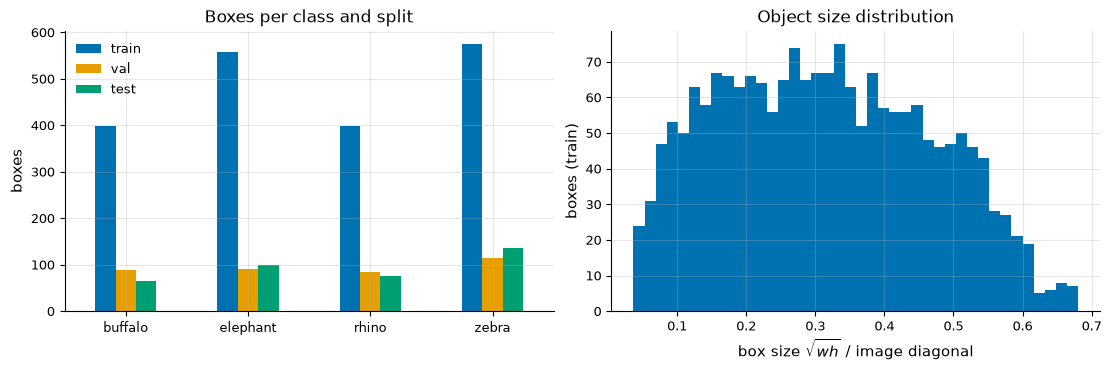

,train,val,test
buffalo,399,89,66
elephant,558,91,99
rhino,399,85,75
zebra,575,114,135
images,1052,225,227


In [2]:
# --- Load all three splits and summarise class counts and box sizes ---
# Each Sample holds the image path, its size and the GT boxes (pixels, xyxy) + class ids.
splits = {sp: detlib.load_split(DATA, sp) for sp in ("train", "val", "test")}
counts = pd.DataFrame({sp: np.bincount(np.concatenate([s.classes for s in ss]), minlength=4)
                       for sp, ss in splits.items()}, index=CLASSES)
counts.loc["images"] = [len(ss) for ss in splits.values()]
val = splits["val"]
rel_size = np.concatenate([np.sqrt((s.boxes[:, 2] - s.boxes[:, 0]) * (s.boxes[:, 3] - s.boxes[:, 1]))
                           / np.hypot(s.width, s.height) for s in splits["train"]])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
counts.iloc[:4].plot.bar(ax=axes[0], rot=0)
axes[0].set_ylabel("boxes"), axes[0].set_title("Boxes per class and split")
axes[1].hist(rel_size, bins=40, color=viz.color(0, unit=True))
axes[1].set_xlabel("box size $\\sqrt{wh}$ / image diagonal"), axes[1].set_ylabel("boxes (train)")
axes[1].set_title("Object size distribution")
plt.show()
counts

A few validation images with their ground-truth boxes:

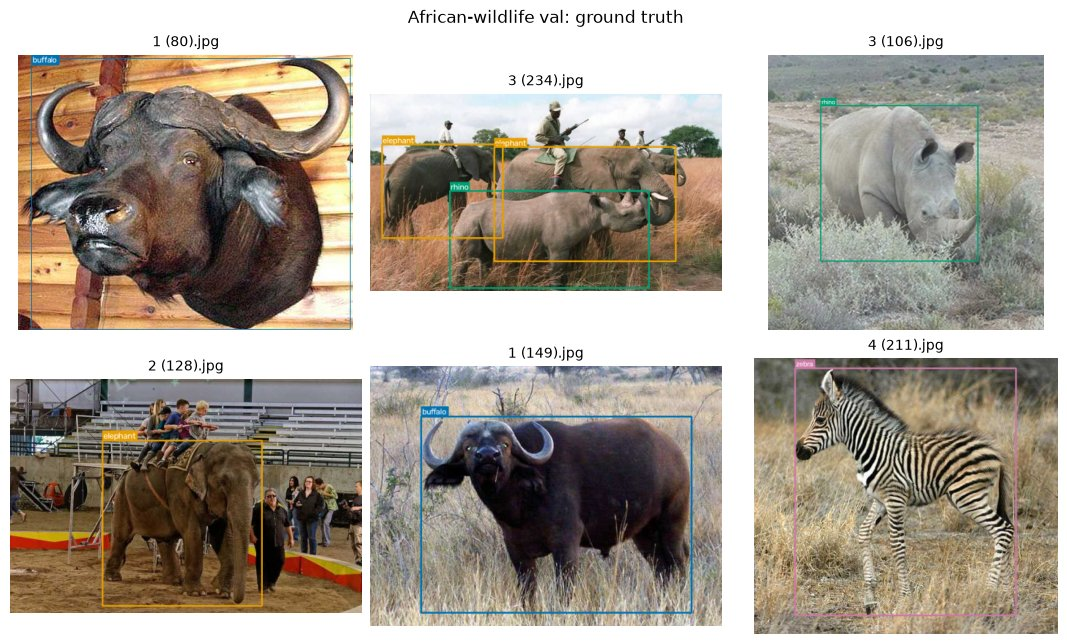

In [3]:
# --- Show ground truth on six validation images ---
# Images are read as RGB and downscaled to 480 px for display (boxes are rescaled to match).
rng = np.random.default_rng(0)
pick = rng.choice(len(val), 6, replace=False)
panels = []
for i in pick:
    s = val[i]
    img = cvio.read_image(s.image)
    panels.append(viz.draw_boxes(img, s.boxes, [CLASSES[c] for c in s.classes], class_ids=s.classes))
show_jpeg(viz.show_images([cvio.resize_max(p, 480) for p in panels], [s.image.name for s in (val[i] for i in pick)],
                          ncols=3, size=3.6, suptitle="African-wildlife val: ground truth"))

## 2. Precision, recall and (m)AP

For one class, sort all predictions in the dataset by confidence. Walking down the list, each
prediction is a **true positive (TP)** if it overlaps a not-yet-matched ground-truth box of that
class with $\mathrm{IoU} \ge t$, otherwise a **false positive (FP)**. After the first $k$ predictions

$$P_k = \frac{TP_k}{TP_k + FP_k}, \qquad R_k = \frac{TP_k}{N_\text{GT}}.$$

The **PR curve** traces $(R_k, P_k)$. **Average precision** is the area under its upper envelope,
which COCO approximates by sampling 101 recall points:

$$\mathrm{AP}_t = \frac{1}{101} \sum_{r \in \{0, 0.01, \dots, 1\}} \max_{R_k \ge r} P_k .$$

**mAP50** averages $\mathrm{AP}_{0.5}$ over classes; **mAP50-95** (the COCO "AP") also averages over
$t \in \{0.50, 0.55, \dots, 0.95\}$, so it rewards precise localisation. AP is threshold-free: it
summarises *all* operating points, which is why evaluation uses a very low confidence threshold
(0.001) and keeps up to 300 boxes per image.

## 3. Zero-shot baseline: the COCO models

A closed-set detector can only output the classes it was trained on. We map COCO
`cow -> buffalo`, `elephant -> elephant`, `zebra -> zebra` and drop every other COCO class; rhino
has no counterpart, so its AP must be 0. The evaluator is `detlib.evaluate`, the from-scratch
implementation of the formulas above.

In [4]:
# --- Zero-shot evaluation of COCO YOLO26n/s on African-wildlife val via a class mapping ---
# conf=0.001 and max_det=300 follow the standard mAP protocol; batch=16 for throughput.
COCO_TO_WILDLIFE = {19: 0, 20: 1, 22: 3}  # cow->buffalo, elephant, zebra; no rhino in COCO


def predict_split(model, samples, class_map=None, conf=0.001, nms=None):
    # Run model.predict over a split in chunks; returns one detlib.Detections per image.
    preds = []
    for i in range(0, len(samples), 32):
        paths = [str(s.image) for s in samples[i:i + 32]]
        for r in model.predict(paths, conf=conf, nms=nms, max_det=300, batch=16, verbose=False):
            preds.append(detlib.ultralytics_to_detections(r, class_map))
    return preds


evals, rows = {}, []
for k in ("yolo26n", "yolo26s"):
    with cvdevice.track_vram() as mem:
        t0 = time.perf_counter()
        preds = predict_split(YOLO(f"{k}.pt"), val, COCO_TO_WILDLIFE)
        sec = time.perf_counter() - t0
    evals[(k, "zero-shot COCO")] = (detlib.evaluate(val, preds, CLASSES), preds)
    res = evals[(k, "zero-shot COCO")][0]
    rows.append({"model": k, "weights": "zero-shot COCO", "mAP50": res.map50, "mAP50-95": res.map50_95,
                 **{f"AP50-95 {c}": v["AP50-95"] for c, v in res.per_class().items()},
                 "eval time [s]": sec, "peak VRAM [MiB]": mem.peak_mb})
pd.DataFrame(rows).set_index(["model", "weights"]).round(3)

,,mAP50,mAP50-95,AP50-95 buffalo,AP50-95 elephant,AP50-95 rhino,AP50-95 zebra,eval time [s],peak VRAM [MiB]
model,weights,,,,,,,,
yolo26n,zero-shot COCO,0.554,0.463,0.426,0.642,0.0,0.783,1.572,941.373
yolo26s,zero-shot COCO,0.608,0.531,0.575,0.729,0.0,0.822,1.993,1424.381


## 4. Fine-tuning: what the training script did

`scripts/train_yolo.py` starts from the COCO checkpoint, replaces the 80-class classification
layers with 4-class ones (the backbone, neck and box regression layers keep their pretrained
weights), and trains with Ultralytics' defaults: `optimizer=auto`, which for a short schedule
(fewer than 10k iterations; here 40 epochs x 66 batches) picks **AdamW** with
$\mathrm{lr} = 0.002 \cdot 5 / (4 + n_c) = 0.00125$; mosaic/HSV/flip augmentation, with mosaic switched
off for the last 10 epochs; AMP mixed precision; 640 px; batch 16. The checkpoint with the best
fitness ($0.1\,\mathrm{mAP50} + 0.9\,\mathrm{mAP50\text{-}95}$ on val) is kept. The logged losses are the
box regression loss and the classification loss of YOLO26's head.

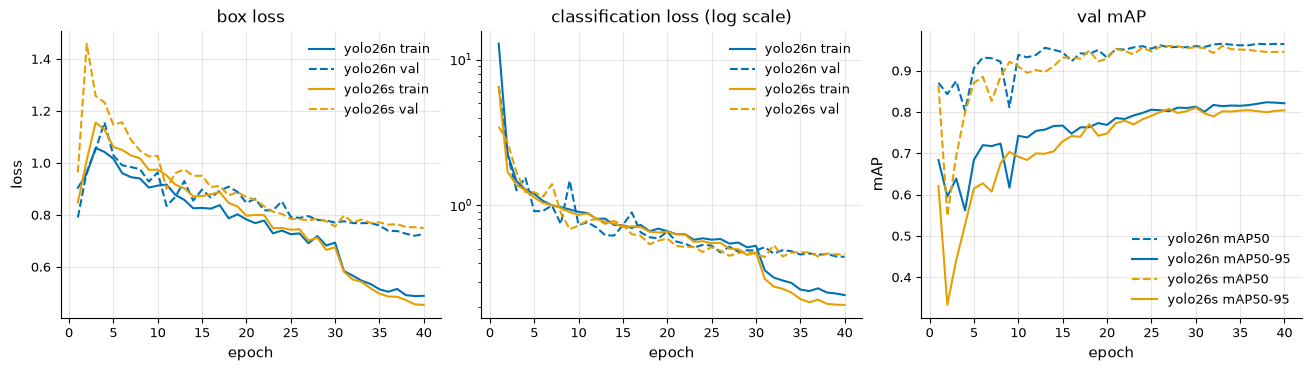

,epochs,batch,imgsz,train time [min],peak train VRAM [MiB]
yolo26n,40.0,16.0,640.0,5.48,2465.6
yolo26s,40.0,16.0,640.0,10.70,4500.0


In [5]:
# --- Training curves from results.csv (both models) ---
# Columns are Ultralytics' per-epoch log; val metrics use the NMS head during training.
logs = {k: pd.read_csv(RESULTS / f"{v}_results.csv") for k, v in RUN_NAMES.items()}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True)
for j, (k, df) in enumerate(logs.items()):
    c = viz.color(j, unit=True)
    axes[0].plot(df["epoch"], df["train/box_loss"], color=c, label=f"{k} train")
    axes[0].plot(df["epoch"], df["val/box_loss"], color=c, ls="--", label=f"{k} val")
    axes[1].plot(df["epoch"], df["train/cls_loss"], color=c, label=f"{k} train")
    axes[1].plot(df["epoch"], df["val/cls_loss"], color=c, ls="--", label=f"{k} val")
    axes[2].plot(df["epoch"], df["metrics/mAP50(B)"], color=c, ls="--", label=f"{k} mAP50")
    axes[2].plot(df["epoch"], df["metrics/mAP50-95(B)"], color=c, label=f"{k} mAP50-95")
axes[1].set_yscale("log")
for ax, t in zip(axes, ["box loss", "classification loss (log scale)", "val mAP"]):
    ax.set_xlabel("epoch"), ax.set_title(t), ax.legend()
axes[0].set_ylabel("loss"), axes[2].set_ylabel("mAP")
viz.savefig(fig, PROJECT, "training_curves")
plt.show()
pd.DataFrame({k: {"epochs": s["epochs"], "batch": s["batch"], "imgsz": s["imgsz"],
                  "train time [min]": s["train_minutes"], "peak train VRAM [MiB]": s["peak_vram_mb"]}
              for k, s in summaries.items()}).T

## 5. Evaluate the fine-tuned models

`model.val()` runs Ultralytics' validator on the val split (conf 0.001, NMS IoU 0.7, rectangular
batches). We run it twice per model: with the default **one-to-many head + NMS** and with
`nms=False`, the **NMS-free one-to-one head**. Then we compute mAP again with `detlib.evaluate`
on predictions from `model.predict` to check that our evaluator agrees.

Small differences are expected: the validator letterboxes whole batches to a common shape, uses a
slightly different matching implementation and interpolates the PR curve with `np.interp`
instead of COCO's step envelope.

In [6]:
# --- Ultralytics val (both heads) + our evaluator, for the fine-tuned n and s models ---
# plots=False and a dedicated output dir keep runs/ultralytics clean; track_vram records peak memory.
ft_models, val_metrics = {}, {}
for k, s in summaries.items():
    ft_models[k] = YOLO(ROOT / s["best_checkpoint"])
    for head_name, nms_arg in [("one-to-many + NMS", None), ("one-to-one", False)]:
        with cvdevice.track_vram() as mem:
            m = ft_models[k].val(data=DATA_YAML, split="val", batch=16, nms=nms_arg, plots=False,
                                 project=str(RUNS), name=f"val_{k}", exist_ok=True, verbose=False)
        val_metrics[(k, head_name)] = m
        rows.append({"model": k, "weights": f"fine-tuned ({head_name}, Ultralytics val)",
                     "mAP50": m.box.map50, "mAP50-95": m.box.map,
                     **{f"AP50-95 {c}": m.box.maps[i] for i, c in enumerate(CLASSES)},
                     "eval time [s]": sum(m.speed.values()) * len(val) / 1000, "peak VRAM [MiB]": mem.peak_mb})
    with cvdevice.track_vram() as mem:
        t0 = time.perf_counter()
        preds = predict_split(ft_models[k], val)
        sec = time.perf_counter() - t0
    res = detlib.evaluate(val, preds, CLASSES)
    evals[(k, "fine-tuned")] = (res, preds)
    rows.append({"model": k, "weights": "fine-tuned (one-to-many + NMS, detlib)", "mAP50": res.map50,
                 "mAP50-95": res.map50_95, **{f"AP50-95 {c}": v["AP50-95"] for c, v in res.per_class().items()},
                 "eval time [s]": sec, "peak VRAM [MiB]": mem.peak_mb})
table = pd.DataFrame(rows).set_index(["model", "weights"])
table.round(3)

mAP50  mAP50-95  \
model   weights                                                            
yolo26n zero-shot COCO                                   0.554     0.463   
yolo26s zero-shot COCO                                   0.608     0.531   
yolo26n fine-tuned (one-to-many + NMS, Ultralytics val)  0.963     0.822   
        fine-tuned (one-to-one, Ultralytics val)         0.955     0.807   
        fine-tuned (one-to-many + NMS, detlib)           0.955     0.813   
yolo26s fine-tuned (one-to-many + NMS, Ultralytics val)  0.957     0.813   
        fine-tuned (one-to-one, Ultralytics val)         0.956     0.801   
        fine-tuned (one-to-many + NMS, detlib)           0.946     0.795   

                                                         AP50-95 buffalo  \
model   weights                                                            
yolo26n zero-shot COCO                                             0.426   
yolo26s zero-shot COCO                                             0.575   
yolo26n fine-tuned (one-to-many + NMS, Ultralytics val)            0.842   
        fine-tuned (one-to-one, Ultralytics val)                   0.817   
        fine-tuned (one-to-many + NMS, detlib)                     0.814   
yolo26s fine-tuned (one-to-many + NMS, Ultralytics val)            0.827   
        fine-tuned (one-to-one, Ultralytics val)                   0.816   
        fine-tuned (one-to-many + NMS, detlib)                     0.808   

                                                         AP50-95 elephant  \
model   weights                                                             
yolo26n zero-shot COCO                                              0.642   
yolo26s zero-shot COCO                                              0.729   
yolo26n fine-tuned (one-to-many + NMS, Ultralytics val)             0.787   
        fine-tuned (one-to-one, Ultralytics val)                    0.785   
        fine-tuned (one-to-many + NMS, detlib)                      0.792   
yolo26s fine-tuned (one-to-many + NMS, Ultralytics val)             0.818   
        fine-tuned (one-to-one, Ultralytics val)                    0.808   
        fine-tuned (one-to-many + NMS, detlib)                      0.779   

                                                         AP50-95 rhino  \
model   weights                                                          
yolo26n zero-shot COCO                                           0.000   
yolo26s zero-shot COCO                                           0.000   
yolo26n fine-tuned (one-to-many + NMS, Ultralytics val)          0.869   
        fine-tuned (one-to-one, Ultralytics val)                 0.836   
        fine-tuned (one-to-many + NMS, detlib)                   0.863   
yolo26s fine-tuned (one-to-many + NMS, Ultralytics val)          0.847   
        fine-tuned (one-to-one, Ultralytics val)                 0.823   
        fine-tuned (one-to-many + NMS, detlib)                   0.841   

                                                         AP50-95 zebra  \
model   weights                                                          
yolo26n zero-shot COCO                                           0.783   
yolo26s zero-shot COCO                                           0.822   
yolo26n fine-tuned (one-to-many + NMS, Ultralytics val)          0.792   
        fine-tuned (one-to-one, Ultralytics val)                 0.789   
        fine-tuned (one-to-many + NMS, detlib)                   0.781   
yolo26s fine-tuned (one-to-many + NMS, Ultralytics val)          0.759   
        fine-tuned (one-to-one, Ultralytics val)                 0.757   
        fine-tuned (one-to-many + NMS, detlib)                   0.753   

                                                         eval time [s]  \
model   weights                                                          
yolo26n zero-shot COCO                                           1.572   
yolo26s zero-shot COCO                                      

### Per-class PR curves: before vs after

Each curve is the raw $(R_k, P_k)$ trace at IoU 0.5 from `detlib.evaluate`. A curve hugging the
top-right corner means high precision at high recall. The zero-shot rhino curve does not exist.

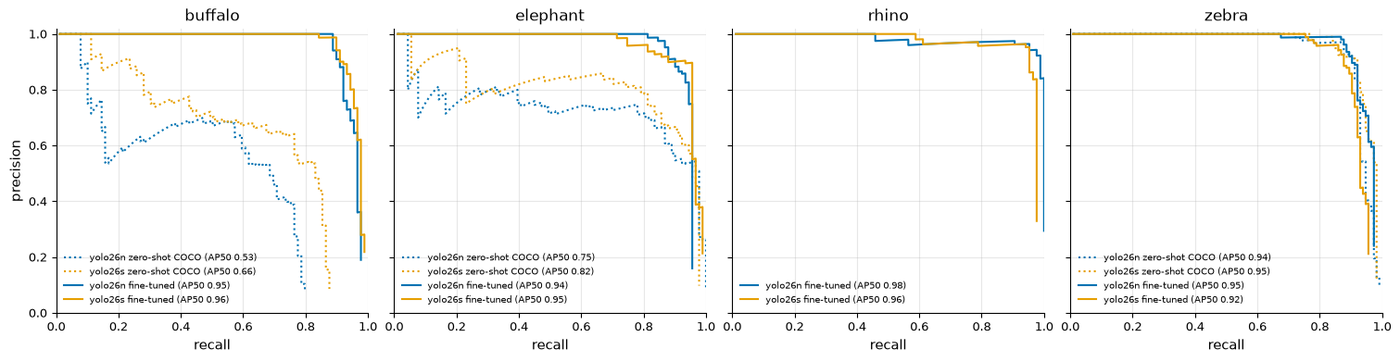

In [7]:
# --- PR curves at IoU 0.5 per class: zero-shot COCO vs fine-tuned (YOLO26n and YOLO26s) ---
# The legend carries AP50 for each curve.
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), constrained_layout=True, sharey=True)
styles = {("yolo26n", "zero-shot COCO"): (0, ":"), ("yolo26s", "zero-shot COCO"): (1, ":"),
          ("yolo26n", "fine-tuned"): (0, "-"), ("yolo26s", "fine-tuned"): (1, "-")}
for c, ax in enumerate(axes):
    for key, (ci, ls) in styles.items():
        res = evals[key][0]
        if c in res.pr_curves:
            rec, prec = res.pr_curves[c]
            ax.plot(rec, prec, ls=ls, color=viz.color(ci, unit=True), label=f"{key[0]} {key[1]} (AP50 {res.ap[c, 0]:.2f})")
    ax.set_title(CLASSES[c]), ax.set_xlabel("recall"), ax.set_xlim(0, 1), ax.set_ylim(0, 1.02)
    ax.legend(fontsize=7, loc="lower left")
axes[0].set_ylabel("precision")
viz.savefig(fig, PROJECT, "pr_curves_before_after")
plt.show()

### Confusion matrix

Ultralytics accumulates a confusion matrix at conf 0.25 / IoU 0.45 during validation: rows are the
predicted class, columns the true class, and the extra "background" row/column counts false
positives (predicted, no matching object) and missed objects (true object, no prediction).

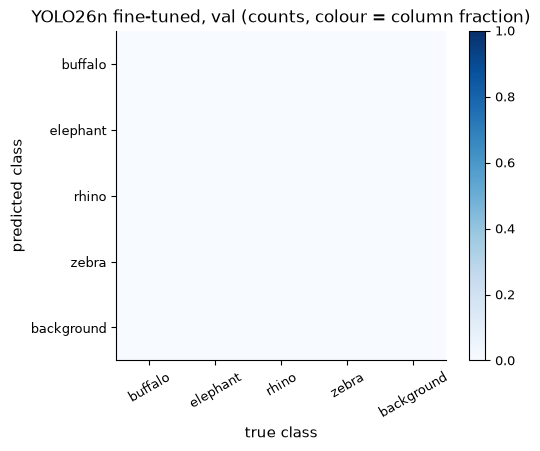

In [8]:
# --- Confusion matrix of the fine-tuned YOLO26n (NMS head) ---
# Column-normalised so each column shows where the objects of one true class ended up.
cm = val_metrics[("yolo26n", "one-to-many + NMS")].confusion_matrix.matrix
labels = CLASSES + ["background"]
cm_norm = cm / np.maximum(cm.sum(0, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(5.2, 4.4), constrained_layout=True)
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for i in range(len(labels)):
    for j in range(len(labels)):
        if cm[i, j] > 0:
            ax.text(j, i, f"{int(cm[i, j])}", ha="center", va="center", fontsize=8,
                    color="white" if cm_norm[i, j] > 0.5 else "black")
ax.set_xticks(range(len(labels)), labels, rotation=30), ax.set_yticks(range(len(labels)), labels)
ax.set_xlabel("true class"), ax.set_ylabel("predicted class"), ax.grid(False)
ax.set_title("YOLO26n fine-tuned, val (counts, colour = column fraction)")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.show()

## 6. Choosing an operating point

mAP summarises every threshold, but a robot must commit to one. At IoU 0.5 we sweep the
confidence threshold $t$ and compute precision, recall and $F_1 = 2PR/(P+R)$ over all classes.
Where to sit on that curve is a *system* decision: a picking robot that triggers a grasp on every
detection wants high precision; a safety monitor that must never miss a person wants high recall.

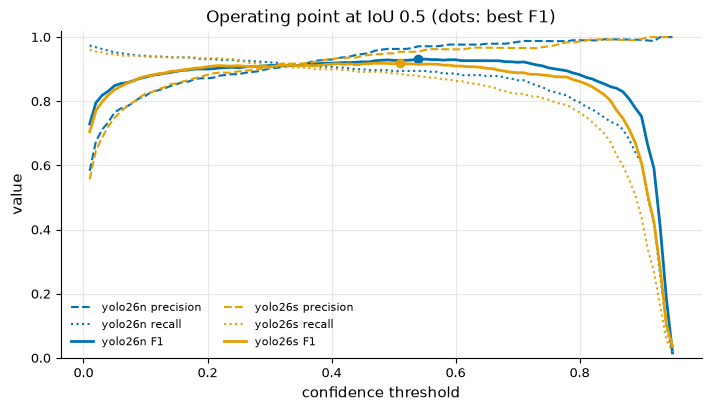

,best-F1 conf,precision,recall,F1
model,,,,
yolo26n,0.54,0.971,0.894,0.931
yolo26s,0.51,0.955,0.887,0.919


In [9]:
# --- Precision / recall / F1 vs confidence threshold for both fine-tuned models ---
# detection_flags gives per-prediction TP flags once; thresholding them is equivalent to re-matching.
n_gt = sum(len(s.classes) for s in val)
ts = np.linspace(0.01, 0.95, 95)
op_rows = []
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
for j, k in enumerate(("yolo26n", "yolo26s")):
    scores, _, tp = detlib.detection_flags(val, evals[(k, "fine-tuned")][1], 0.5)
    P = np.array([tp[scores >= t].mean() if (scores >= t).any() else 1.0 for t in ts])
    R = np.array([tp[scores >= t].sum() / n_gt for t in ts])
    F = 2 * P * R / np.maximum(P + R, 1e-9)
    c = viz.color(j, unit=True)
    ax.plot(ts, P, color=c, ls="--", label=f"{k} precision")
    ax.plot(ts, R, color=c, ls=":", label=f"{k} recall")
    ax.plot(ts, F, color=c, lw=2, label=f"{k} F1")
    b = int(F.argmax())
    ax.plot(ts[b], F[b], "o", color=c)
    op_rows.append({"model": k, "best-F1 conf": ts[b], "precision": P[b], "recall": R[b], "F1": F[b]})
ax.set_xlabel("confidence threshold"), ax.set_ylabel("value"), ax.set_ylim(0, 1.02)
ax.set_title("Operating point at IoU 0.5 (dots: best F1)"), ax.legend(ncol=2, fontsize=8)
plt.show()
op = pd.DataFrame(op_rows).set_index("model")
op.round(3)

## 7. Qualitative results and failure cases

Green boxes are ground truth, coloured boxes are YOLO26n predictions at its best-F1 threshold.
The second grid shows the six validation images with the most errors (FP + FN at IoU 0.5), which
is where to look before collecting more data.

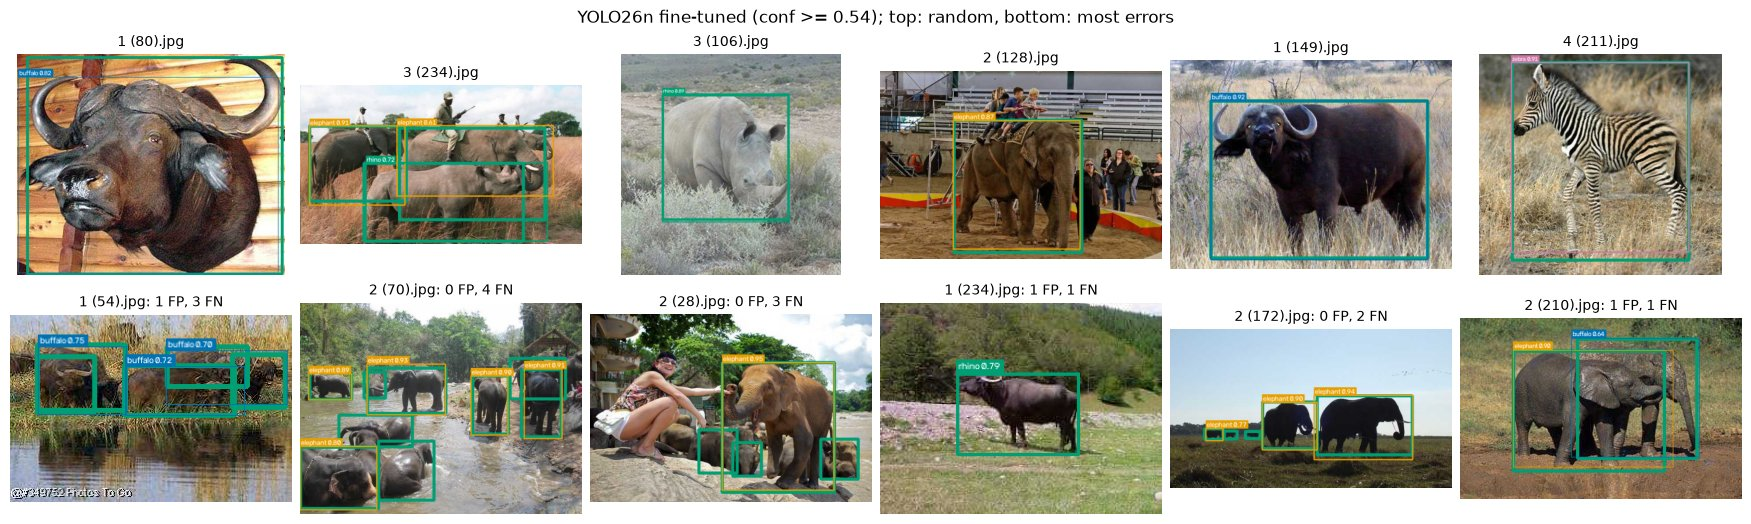

images with zero errors: 190 / 225; total FP 10, FN 40


In [10]:
# --- Predictions vs ground truth on random and on the worst validation images ---
# Errors per image: false positives (unmatched predictions) + missed GT boxes, at the best-F1 threshold.
k = "yolo26n"
t_op = op.loc[k, "best-F1 conf"]
preds = evals[(k, "fine-tuned")][1]
scores, img_idx, tp = detlib.detection_flags(val, preds, 0.5)
keep = scores >= t_op
fp = np.bincount(img_idx[keep & ~tp], minlength=len(val))
fn = np.array([len(s.classes) for s in val]) - np.bincount(img_idx[keep & tp], minlength=len(val))
errors = fp + fn


def render(i):
    s, p = val[i], preds[i]
    sel = p.scores >= t_op
    img = viz.draw_boxes(cvio.read_image(s.image), s.boxes, thickness=6, class_ids=[2] * len(s.boxes))
    img = viz.draw_boxes(img, p.boxes[sel], [CLASSES[c] for c in p.classes[sel]], p.scores[sel], p.classes[sel])
    return cvio.resize_max(img, 480)


worst = np.argsort(-errors, kind="stable")[:6]
grid = [render(i) for i in pick] + [render(i) for i in worst]
titles = [f"{val[i].image.name}" for i in pick] + [f"{val[i].image.name}: {fp[i]} FP, {fn[i]} FN" for i in worst]
fig = viz.show_images(grid, titles, ncols=6, size=2.9, suptitle=f"YOLO26n fine-tuned (conf >= {t_op:.2f}); top: random, bottom: most errors")
viz.savefig(fig, PROJECT, "qualitative_val")
show_jpeg(fig)
print(f"images with zero errors: {(errors == 0).sum()} / {len(val)}; total FP {fp.sum()}, FN {fn.sum()}")

## Results

Per-class AP50-95 before (zero-shot COCO with class mapping) and after fine-tuning, and the
overall numbers from both evaluators. All numbers are on the 225-image validation split,
measured on an RTX 5060 Laptop GPU (8 GB).

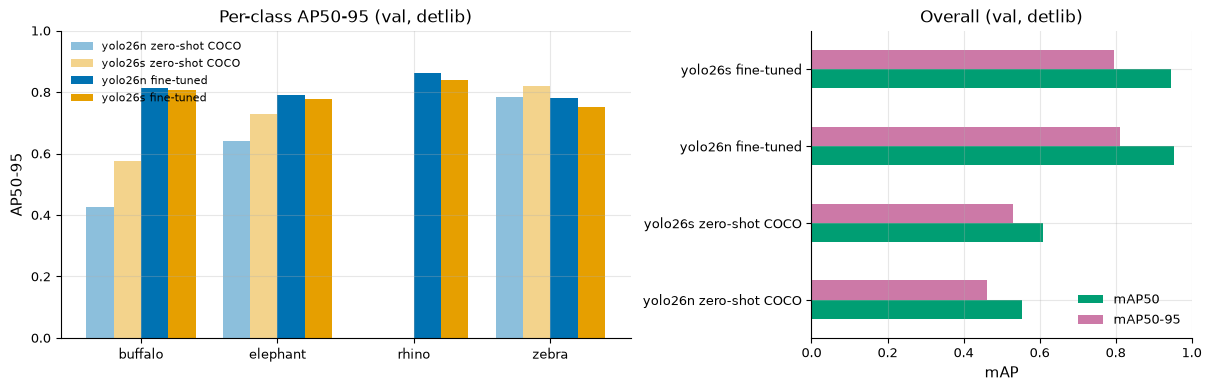

In [11]:
# --- Results figure: per-class AP50-95 before vs after fine-tuning, plus overall mAP ---
# Bars use detlib numbers (same evaluator for both settings, so they are directly comparable).
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True, width_ratios=[3, 2])
keys = [("yolo26n", "zero-shot COCO"), ("yolo26s", "zero-shot COCO"), ("yolo26n", "fine-tuned"), ("yolo26s", "fine-tuned")]
w = 0.2
for j, key in enumerate(keys):
    res = evals[key][0]
    axes[0].bar(np.arange(4) + (j - 1.5) * w, res.ap.mean(1), w, label=f"{key[0]} {key[1]}",
                color=viz.color(j % 2, unit=True), alpha=0.45 if "zero" in key[1] else 1.0)
axes[0].set_xticks(range(4), CLASSES), axes[0].set_ylabel("AP50-95"), axes[0].set_ylim(0, 1)
axes[0].set_title("Per-class AP50-95 (val, detlib)"), axes[0].legend(fontsize=8)
overall = pd.DataFrame({f"{a} {b}": {"mAP50": evals[(a, b)][0].map50, "mAP50-95": evals[(a, b)][0].map50_95}
                        for a, b in keys}).T
overall.plot.barh(ax=axes[1], color=[viz.color(2, unit=True), viz.color(3, unit=True)])
axes[1].set_xlabel("mAP"), axes[1].set_xlim(0, 1), axes[1].set_title("Overall (val, detlib)")
viz.savefig(fig, PROJECT, "map_before_after")
plt.show()

Summary table (all evaluators and heads):

In [12]:
# --- Summary table: mAP for every model / weights / head / evaluator ---
# Adds the training cost from the run summaries for the fine-tuned rows; also saved to results/.
summary = table[["mAP50", "mAP50-95"] + [f"AP50-95 {c}" for c in CLASSES] + ["peak VRAM [MiB]"]].copy()
summary["train time [min]"] = [summaries[m]["train_minutes"] if "fine" in w else np.nan for m, w in summary.index]
summary.round(3).to_csv(RESULTS / "nb02_map.csv")
summary.round(3)

mAP50  mAP50-95  \
model   weights                                                            
yolo26n zero-shot COCO                                   0.554     0.463   
yolo26s zero-shot COCO                                   0.608     0.531   
yolo26n fine-tuned (one-to-many + NMS, Ultralytics val)  0.963     0.822   
        fine-tuned (one-to-one, Ultralytics val)         0.955     0.807   
        fine-tuned (one-to-many + NMS, detlib)           0.955     0.813   
yolo26s fine-tuned (one-to-many + NMS, Ultralytics val)  0.957     0.813   
        fine-tuned (one-to-one, Ultralytics val)         0.956     0.801   
        fine-tuned (one-to-many + NMS, detlib)           0.946     0.795   

                                                         AP50-95 buffalo  \
model   weights                                                            
yolo26n zero-shot COCO                                             0.426   
yolo26s zero-shot COCO                                             0.575   
yolo26n fine-tuned (one-to-many + NMS, Ultralytics val)            0.842   
        fine-tuned (one-to-one, Ultralytics val)                   0.817   
        fine-tuned (one-to-many + NMS, detlib)                     0.814   
yolo26s fine-tuned (one-to-many + NMS, Ultralytics val)            0.827   
        fine-tuned (one-to-one, Ultralytics val)                   0.816   
        fine-tuned (one-to-many + NMS, detlib)                     0.808   

                                                         AP50-95 elephant  \
model   weights                                                             
yolo26n zero-shot COCO                                              0.642   
yolo26s zero-shot COCO                                              0.729   
yolo26n fine-tuned (one-to-many + NMS, Ultralytics val)             0.787   
        fine-tuned (one-to-one, Ultralytics val)                    0.785   
        fine-tuned (one-to-many + NMS, detlib)                      0.792   
yolo26s fine-tuned (one-to-many + NMS, Ultralytics val)             0.818   
        fine-tuned (one-to-one, Ultralytics val)                    0.808   
        fine-tuned (one-to-many + NMS, detlib)                      0.779   

                                                         AP50-95 rhino  \
model   weights                                                          
yolo26n zero-shot COCO                                           0.000   
yolo26s zero-shot COCO                                           0.000   
yolo26n fine-tuned (one-to-many + NMS, Ultralytics val)          0.869   
        fine-tuned (one-to-one, Ultralytics val)                 0.836   
        fine-tuned (one-to-many + NMS, detlib)                   0.863   
yolo26s fine-tuned (one-to-many + NMS, Ultralytics val)          0.847   
        fine-tuned (one-to-one, Ultralytics val)                 0.823   
        fine-tuned (one-to-many + NMS, detlib)                   0.841   

                                                         AP50-95 zebra  \
model   weights                                                          
yolo26n zero-shot COCO                                           0.783   
yolo26s zero-shot COCO                                           0.822   
yolo26n fine-tuned (one-to-many + NMS, Ultralytics val)          0.792   
        fine-tuned (one-to-one, Ultralytics val)                 0.789   
        fine-tuned (one-to-many + NMS, detlib)                   0.781   
yolo26s fine-tuned (one-to-many + NMS, Ultralytics val)          0.759   
        fine-tuned (one-to-one, Ultralytics val)                 0.757   
        fine-tuned (one-to-many + NMS, detlib)                   0.753   

                                                         peak VRAM [MiB]  \
model   weights                                                            
yolo26n zero-shot COCO                                           941.373   
yolo26s zero-shot COCO                                

### Takeaways

* **Closed-set models are blind to new classes.** Zero-shot, YOLO26s reaches AP50-95 0.729 on
  elephant and 0.822 on zebra, only 0.575 on buffalo (a "cow" is not a buffalo) and exactly 0 on
  rhino, for a mAP50-95 of 0.531 (YOLO26n: 0.463). Open-vocabulary detectors (project 04) attack this
  limitation; fine-tuning is the classic fix.
* **A few minutes of fine-tuning closes most of the gap.** 40 epochs on 1052 images (5.5 min for
  YOLO26n, 10.7 min for YOLO26s) lift mAP50-95 to 0.822 / 0.813 (Ultralytics val, NMS head). The
  new class rhino goes from 0 to 0.869 and buffalo from 0.426 to 0.842 (YOLO26n).
* **But not every class improves.** For YOLO26s, zebra *drops* from 0.822 zero-shot to 0.759 after
  fine-tuning (YOLO26n zebra barely moves: 0.783 -> 0.792). Fine-tuning optimises the average over
  the new label set and annotation style; classes the base model already knew well can regress.
  Always check per-class numbers, not just the mean.
* **Bigger was not better here.** YOLO26s did not beat YOLO26n (0.813 vs 0.822 mAP50-95) despite
  2x the training time and 1.8x the training memory (4500 vs 2466 MiB). With 225 validation images,
  differences of about 0.01 are within noise, and the larger model would likely need more data or
  a longer schedule. Measure; do not assume.
* **Training dynamics:** val mAP50 plateaus around 0.95 by epoch 25, while mAP50-95 is still
  creeping up at epoch 40 (localisation keeps improving). The sharp drop of the *training* losses at
  epoch 31 is where mosaic augmentation is switched off, not a sign of overfitting.
* **Both heads give similar accuracy.** The NMS-free one-to-one head scores 1.2-1.5 points lower
  mAP50-95 (0.807 vs 0.822 for n, 0.801 vs 0.813 for s) and almost the same mAP50.
* **Our evaluator agrees with Ultralytics' to within 0.02 mAP50-95** (0.813 vs 0.822 for n, 0.795 vs
  0.813 for s); the gap comes from batch letterboxing, matching and PR interpolation details. That
  is a useful sanity check whenever you report numbers from your own pipeline.
* **mAP is not an operating point.** At the best-F1 threshold (0.54 for YOLO26n: precision 0.971,
  recall 0.894) 190 of 225 validation images are error-free, and misses dominate (40 FN vs 10 FP):
  partly occluded animals in herds and a few buffalo/rhino/elephant confusions, visible in the
  failure gallery.

## Exercises

Solutions are in `projects/03_object_detection/solutions/`.

**Exercise 1 - a second domain.** Fine-tune YOLO26n on `medical-pills.yaml` (92 train / 23 val
images, one class) with `scripts/train_yolo.py` and evaluate it with `detlib.evaluate`. Compare with
the wildlife result: what does a single class and a tiny val split do to the reliability of mAP?

In [13]:
# --- Exercise 1: fine-tune on medical-pills and evaluate ---
# TODO: run `python projects/03_object_detection/scripts/train_yolo.py --data medical-pills.yaml
#       --epochs 30 --name yolo26n_pills` (under the GPU lock), then load best.pt and evaluate the
#       val split of data/ultralytics/medical-pills with predict_split + detlib.evaluate.

**Exercise 2 - generalisation gap.** We selected the best checkpoint on val, so val is slightly
optimistic. Evaluate both fine-tuned models on the held-out **test** split (227 images) and compare
mAP50-95 per class with the val numbers.

In [14]:
# --- Exercise 2: test-split evaluation ---
# TODO: preds = predict_split(ft_models[k], splits["test"]); detlib.evaluate(splits["test"], preds, CLASSES)
#       for k in ("yolo26n", "yolo26s"), and tabulate val vs test mAP50-95 per class.

**Exercise 3 - size-stratified AP.** COCO reports AP for small (< 32^2 px), medium and large
objects. Split the val ground truth and predictions by box area and compute AP50-95 per size
bucket for the fine-tuned YOLO26n. Which bucket limits performance here?

In [15]:
# --- Exercise 3: AP by object size ---
# TODO: for each bucket, keep GT boxes with area in the bucket and predictions with area in the
#       bucket (COCO also ignores predictions matched to out-of-bucket GT; a simple filter is fine),
#       then call detlib.evaluate on the filtered samples/predictions.